# Movie Recommendation System
## Phase 2: Exploratory Data Analysis (EDA)

The objective of this notebook is to explore the MovieLens 1M dataset
and identify useful patterns in movie genres, ratings, movie popularity,
and user behavior.

We will use statistical analysis and data visualization to understand
the dataset before developing our recommendation algorithms.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [2]:
from pathlib import Path

DATA_DIR = Path("../data")

movies = pd.read_csv(
    DATA_DIR / "movies.dat",
    sep="::",
    engine="python",
    encoding="latin-1",
    names=["MovieID", "Title", "Genres"]
)

ratings = pd.read_csv(
    DATA_DIR / "ratings.dat",
    sep="::",
    engine="python",
    encoding="latin-1",
    names=["UserID", "MovieID", "Rating", "Timestamp"]
)

users = pd.read_csv(
    DATA_DIR / "users.dat",
    sep="::",
    engine="python",
    encoding="latin-1",
    names=["UserID", "Gender", "Age", "Occupation", "ZipCode"]
)

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [3]:
all_genres = movies["Genres"].str.split("|").explode()

genre_counts = all_genres.value_counts()

genre_counts

Genres
Drama          1603
Comedy         1200
Action          503
Thriller        492
Romance         471
Horror          343
Adventure       283
Sci-Fi          276
Children's      251
Crime           211
War             143
Documentary     127
Musical         114
Mystery         106
Animation       105
Fantasy          68
Western          68
Film-Noir        44
Name: count, dtype: int64

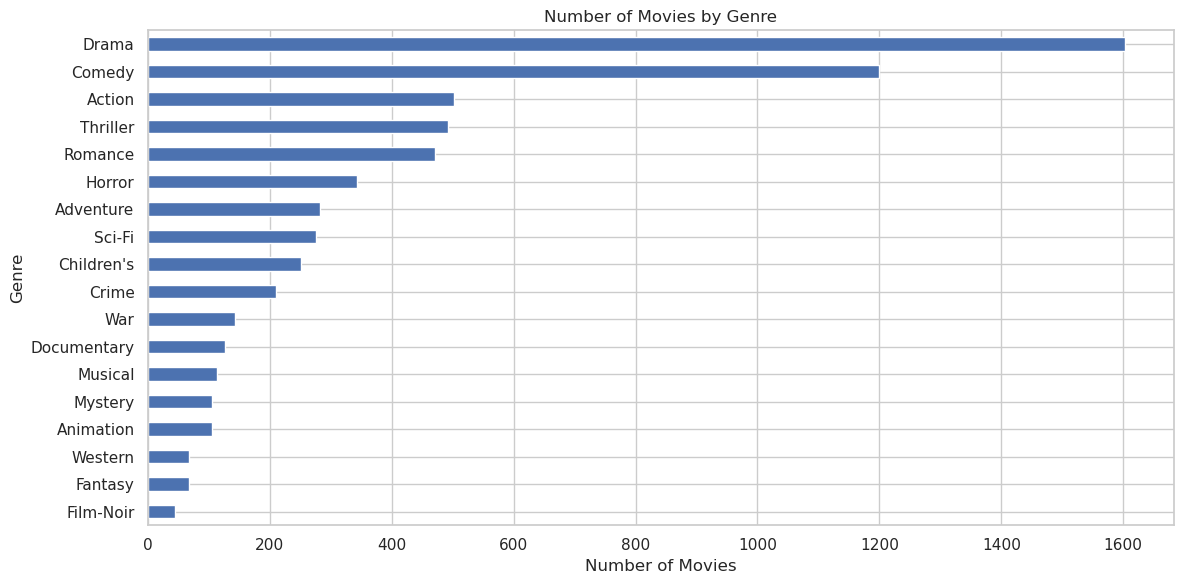

In [4]:
plt.figure(figsize=(12, 6))

genre_counts.sort_values().plot(
    kind="barh"
)

plt.title("Number of Movies by Genre")
plt.xlabel("Number of Movies")
plt.ylabel("Genre")

plt.tight_layout()
plt.show()

In [5]:
rating_counts = ratings["Rating"].value_counts().sort_index()

rating_counts

Rating
1     56174
2    107557
3    261197
4    348971
5    226310
Name: count, dtype: int64

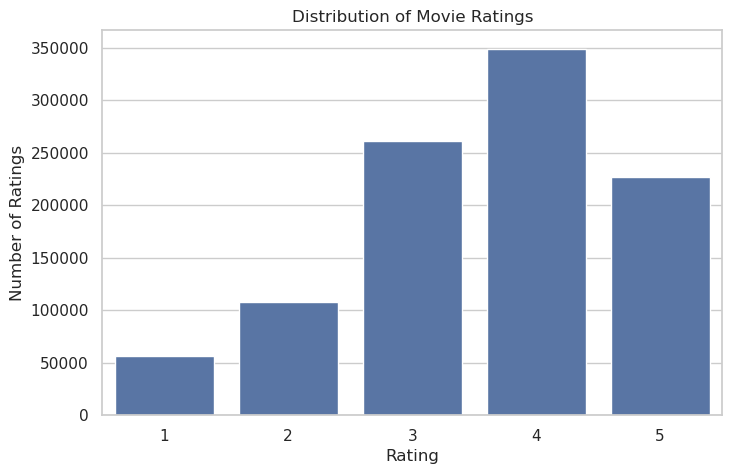

In [6]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=ratings,
    x="Rating"
)

plt.title("Distribution of Movie Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")

plt.show()

In [7]:
average_rating = ratings["Rating"].mean()

print("Average Movie Rating:", round(average_rating, 2))

Average Movie Rating: 3.58


In [8]:
movie_rating_counts = (
    ratings.groupby("MovieID")
    .size()
    .reset_index(name="NumberOfRatings")
)

movie_rating_counts.head()

,MovieID,NumberOfRatings
0,1,2077
1,2,701
2,3,478
3,4,170
4,5,296


In [9]:
popular_movies = movie_rating_counts.merge(
    movies,
    on="MovieID"
)

popular_movies = popular_movies.sort_values(
    by="NumberOfRatings",
    ascending=False
)

popular_movies[["Title", "NumberOfRatings"]].head(10)

,Title,NumberOfRatings
2651,American Beauty (1999),3428
253,Star Wars: Episode IV - A New Hope (1977),2991
1106,Star Wars: Episode V - The Empire Strikes Back...,2990
1120,Star Wars: Episode VI - Return of the Jedi (1983),2883
466,Jurassic Park (1993),2672
1848,Saving Private Ryan (1998),2653
575,Terminator 2: Judgment Day (1991),2649
2374,"Matrix, The (1999)",2590
1178,Back to the Future (1985),2583
579,"Silence of the Lambs, The (1991)",2578


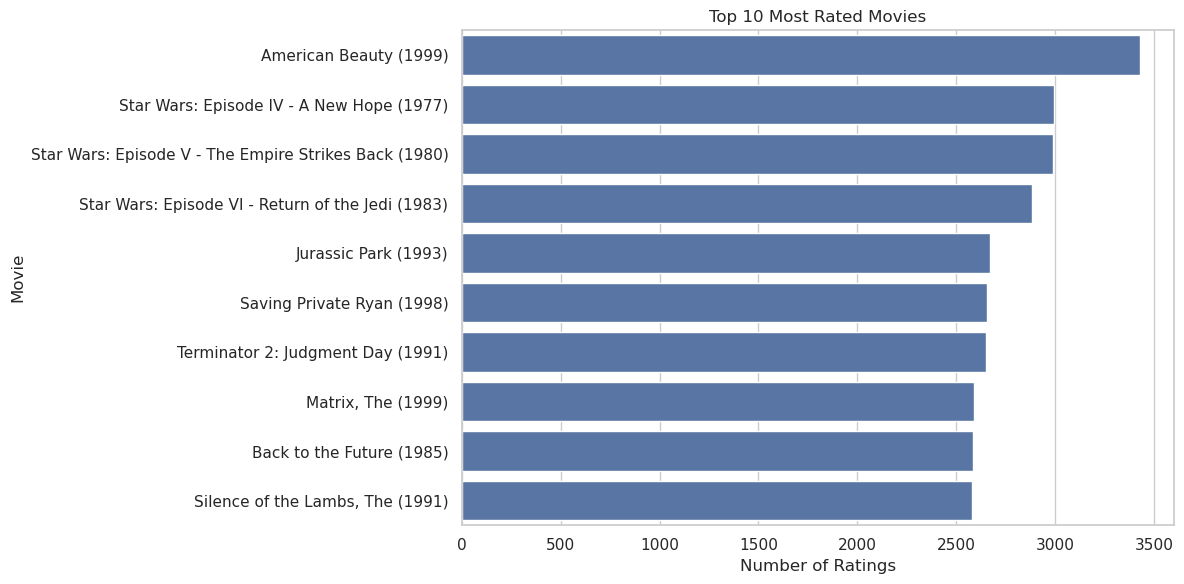

In [10]:
top_10_popular = popular_movies.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_10_popular,
    x="NumberOfRatings",
    y="Title"
)

plt.title("Top 10 Most Rated Movies")
plt.xlabel("Number of Ratings")
plt.ylabel("Movie")

plt.tight_layout()
plt.show()

In [11]:
movie_statistics = (
    ratings.groupby("MovieID")
    .agg(
        AverageRating=("Rating", "mean"),
        NumberOfRatings=("Rating", "count")
    )
    .reset_index()
)

movie_statistics = movie_statistics.merge(
    movies,
    on="MovieID"
)

movie_statistics.head()

,MovieID,AverageRating,NumberOfRatings,Title,Genres
0,1,4.146846,2077,Toy Story (1995),Animation|Children's|Comedy
1,2,3.201141,701,Jumanji (1995),Adventure|Children's|Fantasy
2,3,3.016736,478,Grumpier Old Men (1995),Comedy|Romance
3,4,2.729412,170,Waiting to Exhale (1995),Comedy|Drama
4,5,3.006757,296,Father of the Bride Part II (1995),Comedy


In [12]:
qualified_movies = movie_statistics[
    movie_statistics["NumberOfRatings"] >= 100
]

top_rated_movies = qualified_movies.sort_values(
    by="AverageRating",
    ascending=False
)

top_rated_movies[
    ["Title", "AverageRating", "NumberOfRatings"]
].head(10)

,Title,AverageRating,NumberOfRatings
1839,Seven Samurai (The Magnificent Seven) (Shichin...,4.560510,628
309,"Shawshank Redemption, The (1994)",4.554558,2227
802,"Godfather, The (1972)",4.524966,2223
708,"Close Shave, A (1995)",4.520548,657
49,"Usual Suspects, The (1995)",4.517106,1783
513,Schindler's List (1993),4.510417,2304
1066,"Wrong Trousers, The (1993)",4.507937,882
861,Sunset Blvd. (a.k.a. Sunset Boulevard) (1950),4.491489,470
1108,Raiders of the Lost Ark (1981),4.477725,2514
843,Rear Window (1954),4.476190,1050


In [13]:
user_activity = (
    ratings.groupby("UserID")
    .size()
    .reset_index(name="NumberOfRatings")
)

user_activity.head()

,UserID,NumberOfRatings
0,1,53
1,2,129
2,3,51
3,4,21
4,5,198


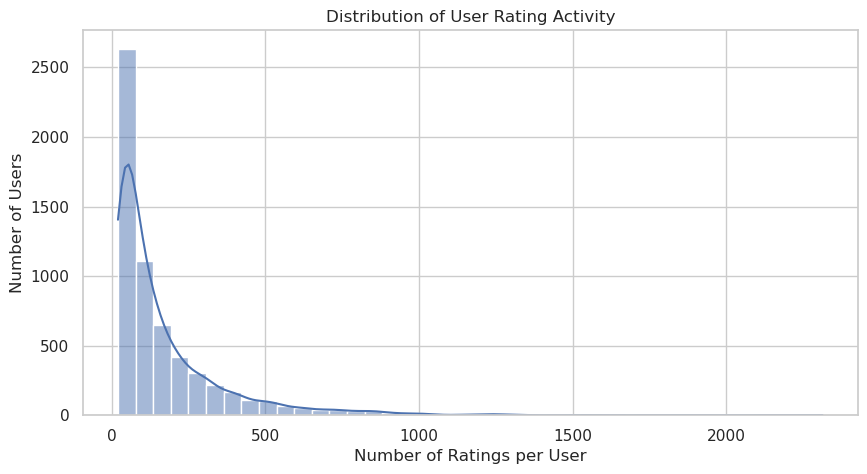

In [14]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=user_activity,
    x="NumberOfRatings",
    bins=40,
    kde=True
)

plt.title("Distribution of User Rating Activity")
plt.xlabel("Number of Ratings per User")
plt.ylabel("Number of Users")

plt.show()